# Linear Regression Workshop
## Predicting Store Revenue

We're using the **Rossmann Store Sales** dataset: daily sales for 1,115 drug stores in Germany from January 2013 to July 2015. Our goal is to **predict a store's sales on a given day**.

--- 

### Plan

1. Load and explore the data
2. Clean the data (what do we do with closed stores?)
3. Split into train and test sets 
4. Look at one feature, then fit a **simple linear regression**
5. Was that fair? (in real life application, would we know these features ahead of time)
6. Look at the rest of the features
7. Fit a **multiple linear regression**
8. Check the model: residuals and coefficients
9. Wrap-up + challenges

--- 

**How this notebook works**

Cells are marked with these emojis.
- ✏️: Write these. The instructions above each one tell you what to do and what to name things so that later cells work.
- 💬: Stop and think, or talk to the people next to you. Answers can go in the markdown cell below the stop and think cell.
- 👀: Observe. These are notes to keep in mind.

Make sure to run each cell as you go (in order), or something later on might not work!


---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option('display.max_colwidth', None)
FILE_PATH = 'data/train.csv'

## 1. Load and explore

| Column | Meaning |
|---|---|
| `Store` | Store ID (1–1115) |
| `DayOfWeek` | 1 = Monday ... 7 = Sunday |
| `Date` | The day |
| `Sales` | **Revenue that day (€). This is our target.** |
| `Customers` | Number of customers that day |
| `Open` | 1 = store was open, 0 = closed |
| `Promo` | 1 = store was running a promotion that day |
| `StateHoliday` | `a` = public holiday, `b` = Easter, `c` = Christmas, `0` = none |
| `SchoolHoliday` | 1 = public schools were closed that day |

✏️ Load the data into a DataFrame called `df` with `pd.read_csv()`, passing it `DATA_URL`. Check how many rows and columns it has (`df.shape`), look at the first few rows (`df.head()`).

In [22]:
df = pd.read_csv(FILE_PATH)

<positron-console-cell-22>:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.


In [23]:
print(df.shape)
df.head()

(1017209, 9)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


✏️ Use `df.describe()` to get a statistical summary table of the data.

In [18]:
df.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


We will build a correlation matrix to examine how each column relates to the others, and plot it as a heatmap to visualize.

**What's correlation?** It's a number between **-1 and 1** that measures how closely two columns move together in a straight-line way.
- **Sign = direction.** Positive means that when one goes up, the other tends to go up too. Negative means that when one goes up, the other tends to go down.
- **Size = strength.** Close to 1 or -1 is a strong relationship, and close to 0 is weak or none.


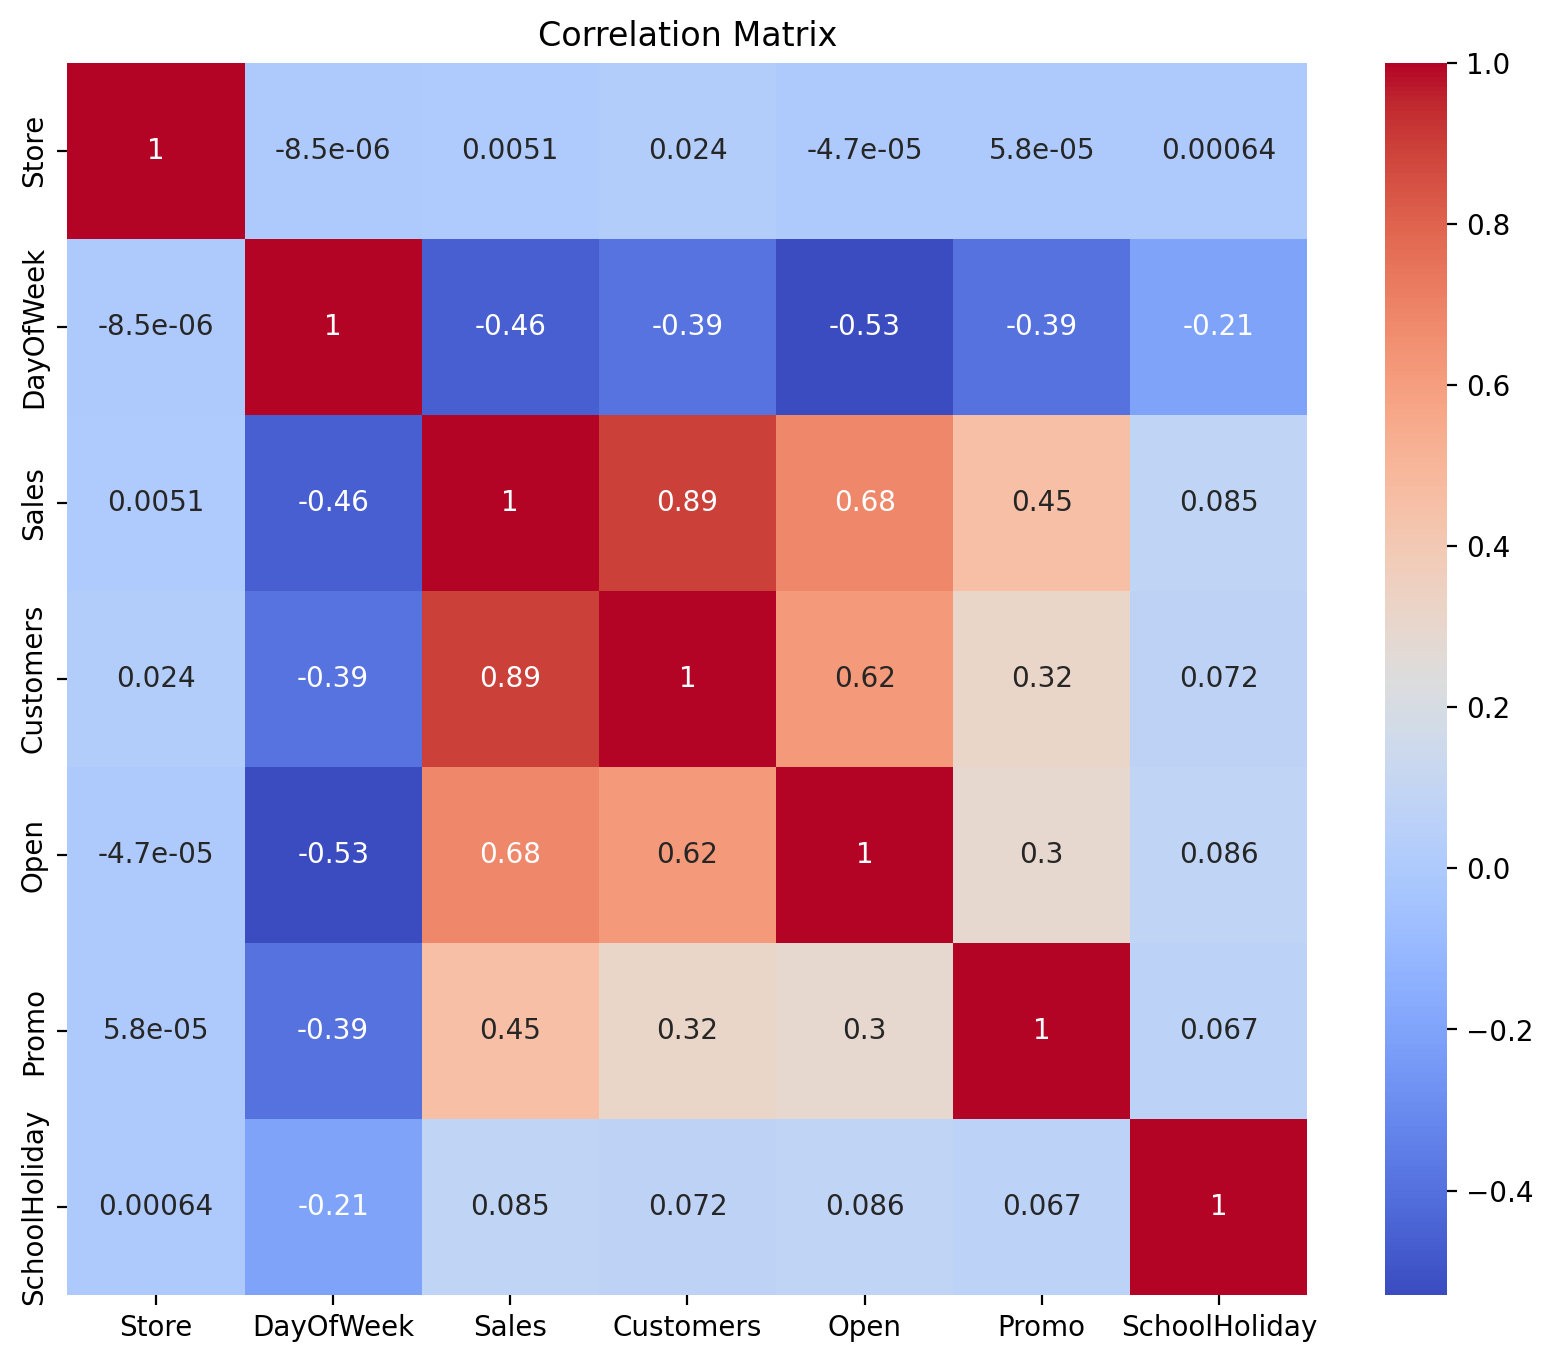

In [24]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

💬 Which feature is most correlated with `Sales`?

(**Note:** look at the size and ignore the sign. A correlation of -0.4 is stronger than one of 0.2, just in the opposite direction.)

*Your answer:*

👀 **Observe**
- `Store` shows up here, but it's an **ID number**. Store 1000 isn't "more" than store 2, so its correlation doesn't mean anything.
- `Open` looks strongly correlated with `Sales`. Part of that is trivial: a closed store sells €0.

Let's see what days make the most sales.

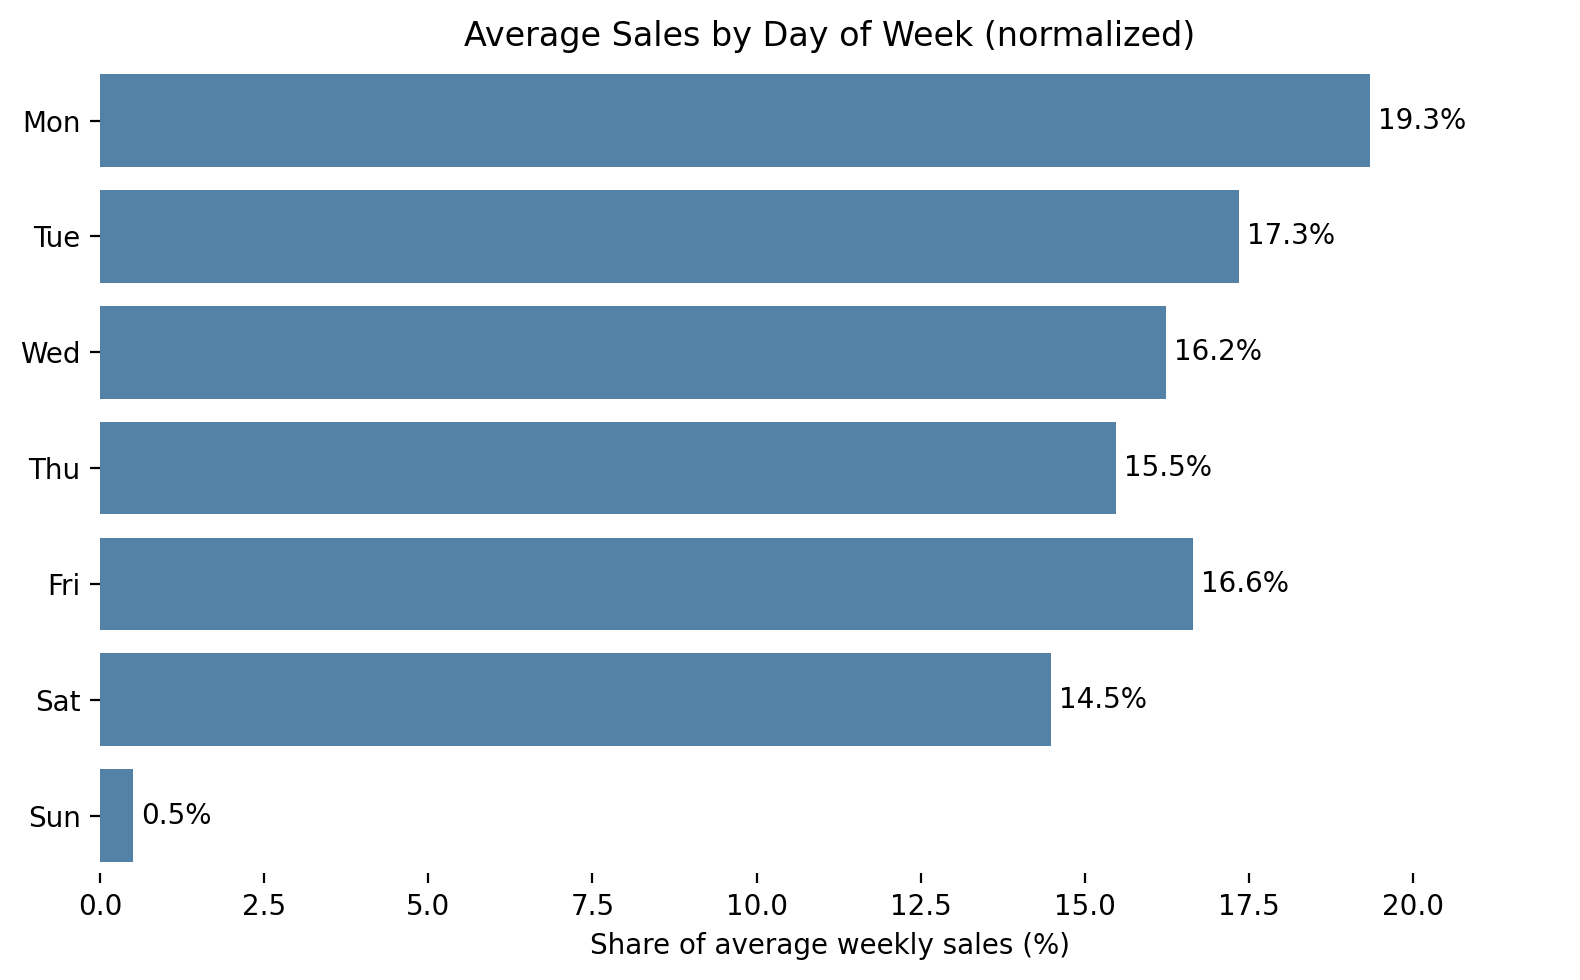

In [25]:
day_names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}

daily = (
    df.groupby("DayOfWeek", as_index=False)["Sales"].mean()
      .assign(Day=lambda d: d["DayOfWeek"].map(day_names),
              Share=lambda d: d["Sales"] / d["Sales"].sum() * 100)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=daily, y="Day", x="Share", order=list(day_names.values()),
            color="steelblue", ax=ax)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlabel("Share of average weekly sales (%)")
ax.set_ylabel("")
ax.set_title("Average Sales by Day of Week (normalized)")
sns.despine(left=True, bottom=True)
ax.set_xlim(0, daily["Share"].max() * 1.15)
plt.tight_layout()
plt.show()

Sunday makes barely any sales compared to the rest of the week! 

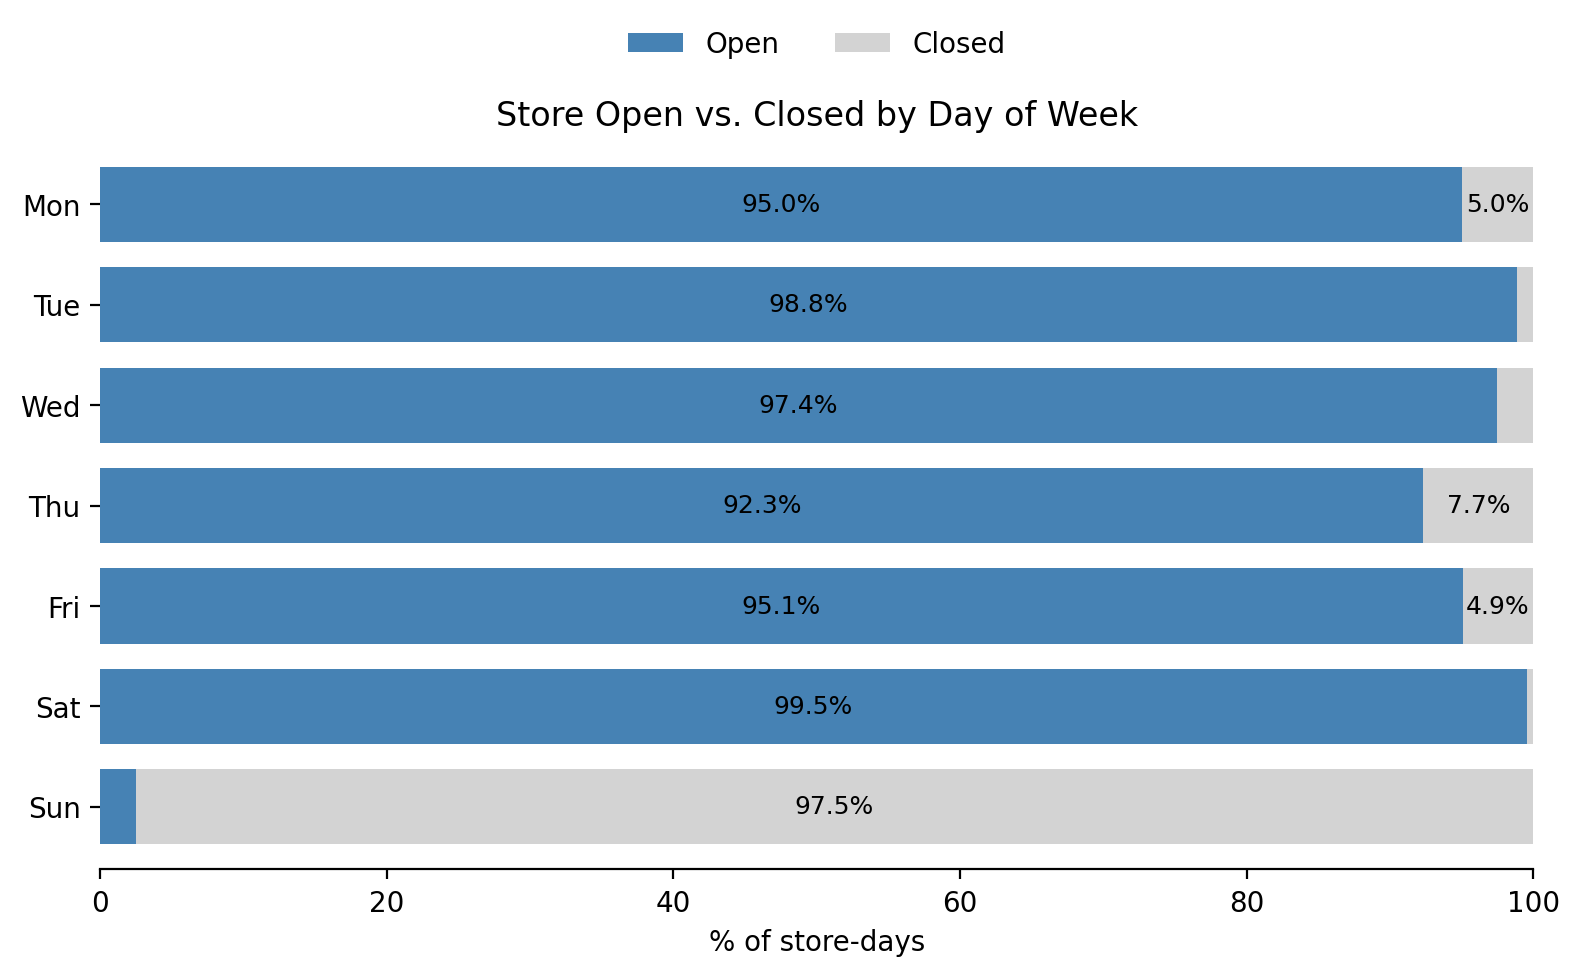

In [26]:
cross_tab = (
    pd.crosstab(df["DayOfWeek"], df["Open"], normalize="index")
      .mul(100)
      .rename(index=day_names, columns={0: "Closed", 1: "Open"})
      [["Open", "Closed"]]
      .iloc[::-1]
)

ax = cross_tab.plot(kind="barh", stacked=True, figsize=(8, 5),
                    color=["steelblue", "lightgray"], width=0.75)

for container in ax.containers:
    labels = [f"{w:.1f}%" if w > 4 else "" for w in container.datavalues]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=9)

ax.set_xlabel("% of store-days")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Store Open vs. Closed by Day of Week")
ax.legend(title="", loc="lower center", bbox_to_anchor=(0.5, 1.08), ncol=2, frameon=False)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

Now we can see why Sunday has the smallest share of weekly sales: **most stores aren't open on Sundays**. If we hadn't checked, we might have assumed something false, like "people don't want to shop on Sundays."

## 2. Clean up: closed stores

A closed store sells €0. We don't need a model to tell us that, and leaving those rows in would make the model spend its effort learning "closed means zero."

So we'll **only model days when the store was open**. There are also a handful of days marked open with €0 sales, which are likely "mistakes" in the data, so we'll drop those too.

We'll also pull the **month** out of the date, since we'll want it later.

In [29]:
print(f"Share of rows where the store was closed: {(df['Open'] == 0).mean():.1%}")
print(f"Open, zero sales: {((df['Open'] == 1) & (df['Sales'] == 0)).sum()} rows")

df['StateHoliday'] = df['StateHoliday'].astype(str)
df_open = df[(df['Open'] == 1) & (df['Sales'] > 0)].copy()
df_open['Date'] = pd.to_datetime(df_open['Date'])
df_open['Month'] = df_open['Date'].dt.month

Share of rows where the store was closed: 17.0%
Open, zero sales: 54 rows


## 3. Train / test split

We train the model on one part of the data and test it on data it has **never seen**. That tells us how well it would do in real life.

In other workshops you may have used `train_test_split`, which **shuffles rows randomly**. That's a problem here. Our rows are days, and a random shuffle would let the model train on June 2015 and then get "tested" on May 2015. It would be using the future to predict the past.

In real life, you predict the future from the past. So we split **temporally** (by date): everything before May 2015 is training data, and May–July 2015 is the test set.

✏️ **Write it**

1. Starting from `df_open`, make `train`: all rows with `Date` **before** `"2015-05-01"`.
2. Make `test`: all rows with `Date` **on or after** `"2015-05-01"`.
3. Check how big the test set is: print what **percentage of `df_open`** ended up in `test`, rounded to 1 decimal place (e.g. `9.8%`).

*Hint 1:* you can filter a DataFrame with a condition, e.g. `df[df["Sales"] > 1000]`. Dates can be compared to strings like `"2015-05-01"`.

*Hint 2:* `len(some_df)` gives you the number of rows. The percentage is (rows in test) ÷ (rows in `df_open`). To print it as a percentage, use an f-string with `:.1%` after the value, e.g. `f"{0.25:.1%}"` prints `25.0%`.

In [30]:
train = df_open[df_open["Date"] < "2015-05-01"]
test  = df_open[df_open["Date"] >= "2015-05-01"]

print(f"Fraction in test: {len(test) / len(df_open):.1%}")

Fraction in test: 10.0%


Let's check what dates each split covers.

In [31]:
print("train:", train.shape, train["Date"].min().date(), "to", train["Date"].max().date())
print("test: ", test.shape,  test["Date"].min().date(),  "to", test["Date"].max().date())

train: (759848, 10) 2013-01-01 to 2015-04-30
test:  (84490, 10) 2015-05-01 to 2015-07-31


## 4. Simple linear regression: one feature

Simple linear regression fits a straight line:

$$\text{Sales} = b_0 + b_1 \cdot x$$

- $b_0$ is the **intercept**: predicted sales when $x = 0$.
- $b_1$ is the **slope**: how much predicted sales change when $x$ goes up by 1.

Before fitting anything, we **look at the feature**. The heatmap said `Customers` is the most correlated with `Sales`, so let's plot them against each other.

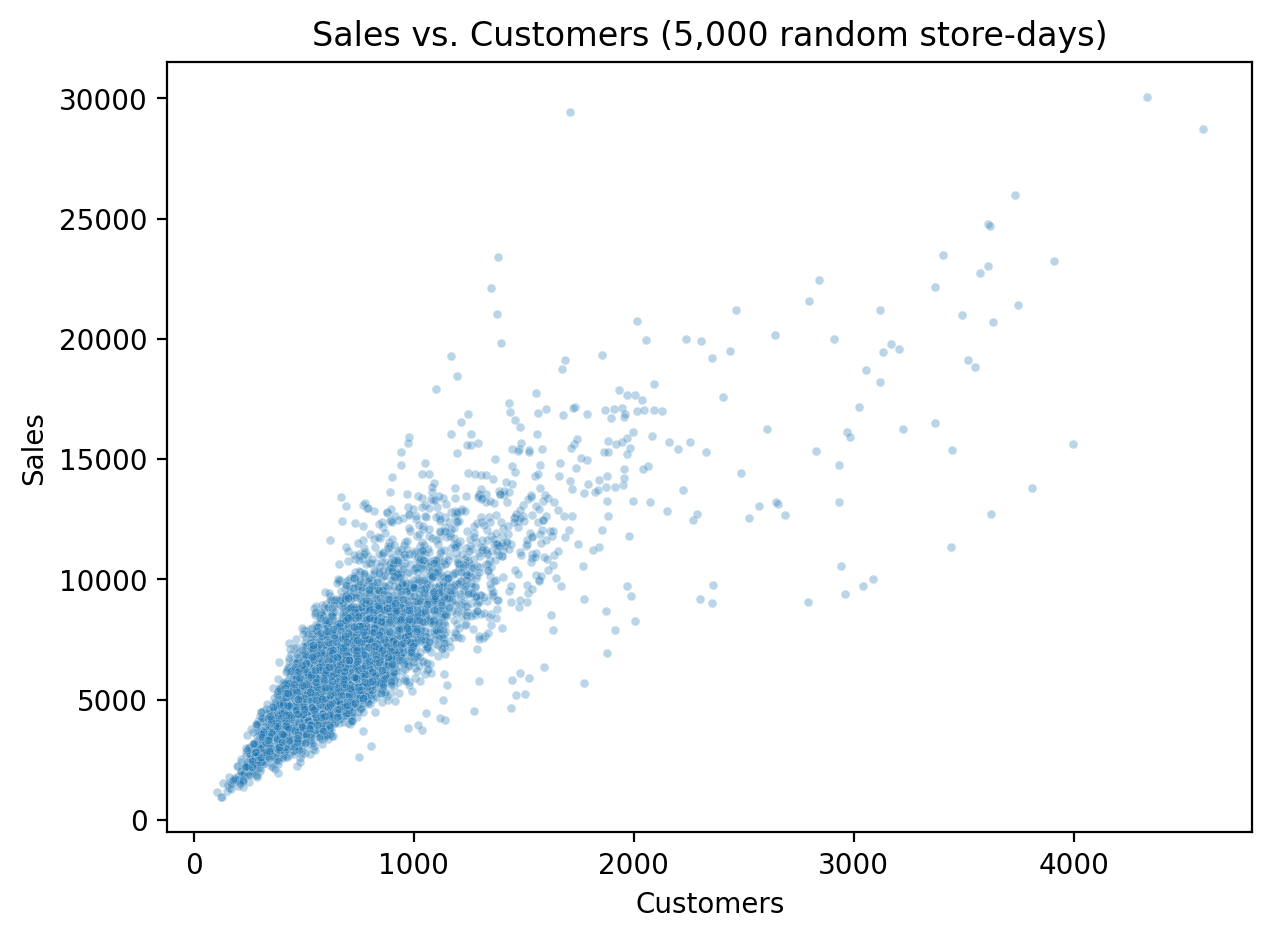

Correlation: 0.826


In [32]:
sample = train.sample(5000, random_state=42)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=sample, x="Customers", y="Sales", alpha=0.3, s=10)
plt.title("Sales vs. Customers (5,000 random store-days)")
plt.show()

print(f"Correlation: {train['Customers'].corr(train['Sales']):.3f}")

💬 **Discuss**
- Does this look like a straight-line relationship?
- Look at the **spread** of the points. Is it the same everywhere, or does it fan out as customers increase? (A fan shape means bigger stores have bigger errors. We'll see this again later.)

*Your answer:*

### ✏️ Fit the simple model
1. Make `X_train` from the `Customers` column of `train`, and `y_train` from the `Sales` column. Do the same for `X_test` and `y_test`.
   - Use **double brackets** for X, i.e.`train[["Customers"]]`. scikit-learn expects X to be a table (2D) even if it has only one column. y is a single column, so single brackets.
2. Create a `LinearRegression()` model and `.fit()` it on the training data.
3. Print the intercept (`.intercept_`) and the slope (`.coef_`).

In [ ]:
X_train = train[["Customers"]]
y_train = train["Sales"]
X_test  = test[["Customers"]]
y_test  = test["Sales"]

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

print(f"Intercept: {simple_model.intercept_:.2f}")
print(f"Slope:     {simple_model.coef_[0]:.2f}")

Intercept: 2051.65
Slope:     6.39


**Reading the results**
- **Slope**: each extra customer adds about this many euros of sales. That's roughly the **average basket size** (the average number of units a customer purchases in a single transaction).
- **Intercept**: predicted sales with 0 customers. Not meaningful here (an open store with no customers sells nothing), it just positions the line

### How do we measure a regression model?

Our model predicts a number (sales in €), so we measure **how far off** its predictions are. Every metric starts from the **error** (also called the **residual**) for each row:

$$\text{error} = \text{actual} - \text{predicted}$$

If a store actually sold €8,000 and we predicted €7,500, the error is €500.

We have tens of thousands of errors, one per test row, so we need a way to sum them up into one number. Here are the common ones.

| Metric | What it does | How to read it | Good is... |
|---|---|---|---|
| **MAE** (Mean Absolute Error) | Average of the errors, ignoring the sign | "On average, we're off by €___" | Lower |
| **MSE** (Mean Squared Error) | Square every error, then average | Units are €², so it's hard to interpret directly | Lower |
| **RMSE** (Root Mean Squared Error) | Square root of MSE | Back in €. Like MAE, but big misses count extra | Lower |
| **R²** (R-squared) | Share of the variation in sales the model explains | 1 = perfect, 0 = no better than always guessing the average | Higher |

**Why not just average the errors?** Positive and negative errors cancel out. Being €1,000 too high on one day and €1,000 too low on another would average to €0, which looks perfect even though both predictions were wrong. MAE fixes this by dropping the sign, and MSE/RMSE fix it by squaring.

**MAE vs. RMSE:** squaring makes big errors count a lot more. One €5,000 miss adds 25,000,000 to the sum of squares, while five €1,000 misses add only 5,000,000 together. So:
- RMSE is always at least as big as MAE.
- If RMSE is **much** bigger than MAE, the model is making a few really big mistakes.

**What we'll use:** **MAE** and **RMSE**, because they're in euros and easy to explain, plus **R²**, because it gives a 0-to-1 sense of how much the model captures.

⚠️ **We always compute these on the test set.** A model can memorize its training data, so only the test set tells us how it would do on days it has never seen.


### ✏️ Predict w/ the simple model

1. Use `.predict()` to get predictions for `X_test`.
2. Compute **R²**, **RMSE**, and **MAE** on the test set using `r2_score`, `mean_squared_error` (take the square root for RMSE), and `mean_absolute_error`.

In [34]:
y_pred_simple = simple_model.predict(X_test)

r2   = r2_score(y_test, y_pred_simple)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_simple))
mae  = mean_absolute_error(y_test, y_pred_simple)

print(f"\nTest R²:   {r2:.3f}")
print(f"Test RMSE: €{rmse:,.0f}")
print(f"Test MAE:  €{mae:,.0f}")


Test R²:   0.632
Test RMSE: €1,863
Test MAE:  €1,319


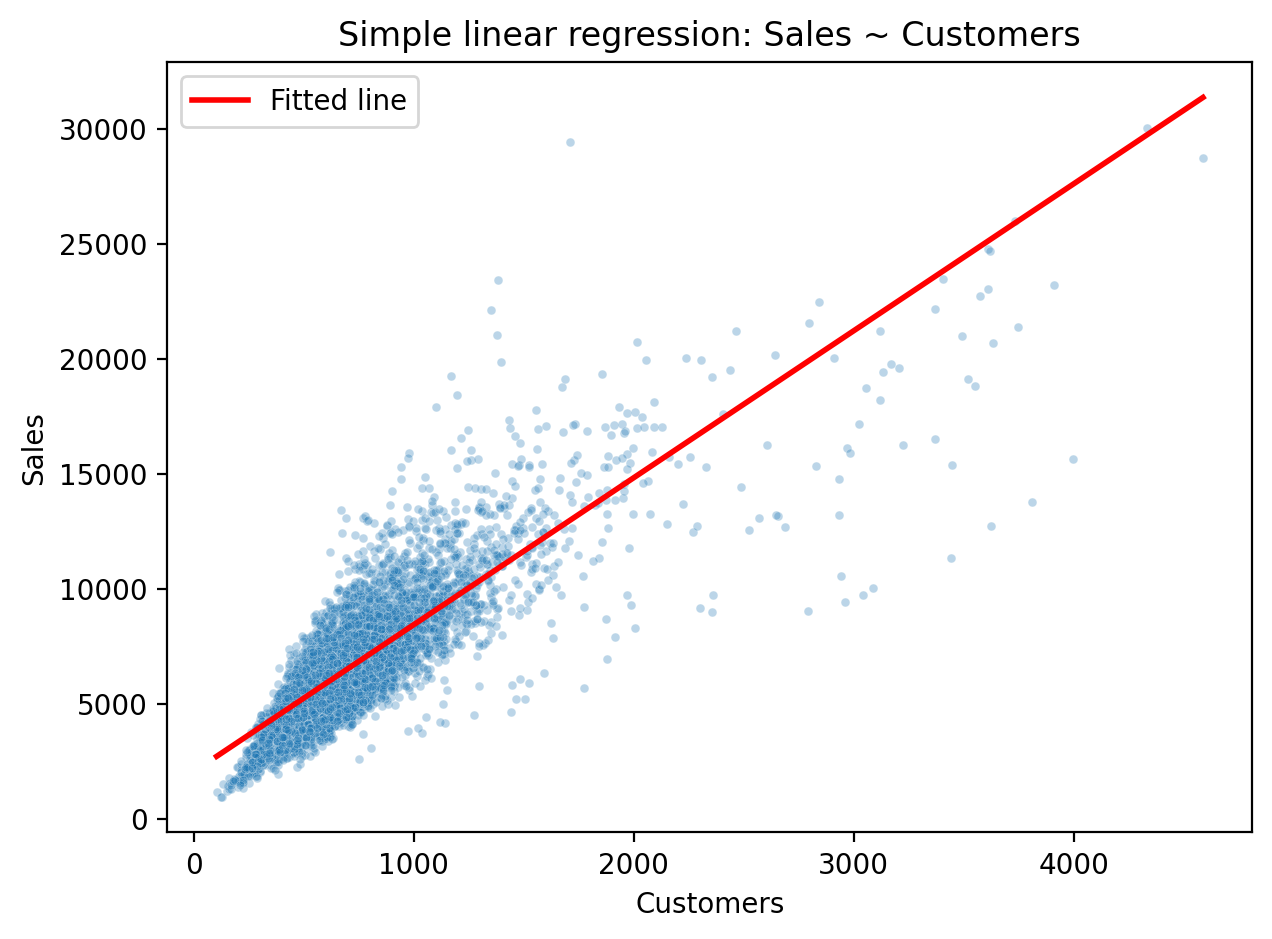

In [35]:
line_x = np.linspace(sample["Customers"].min(), sample["Customers"].max(), 100)
line_y = simple_model.intercept_ + simple_model.coef_[0] * line_x

plt.figure(figsize=(7, 5))
sns.scatterplot(data=sample, x="Customers", y="Sales", alpha=0.3, s=10)
plt.plot(line_x, line_y, color="red", linewidth=2, label="Fitted line")
plt.legend()
plt.title("Simple linear regression: Sales ~ Customers")
plt.show()

💬 **Discuss**

The line captures the overall trend: more customers, more sales. But look closer.

- Is the spread around the line the same everywhere, or does it get wider as customers increase?
- On the right side, are most points above or below the line? What does that mean for our predictions on busy days?
- One slope means we assume every customer spends the same amount. Is that realistic across 1,115 different stores?

So the model isn't perfect. But before we try to improve it, there's a bigger question: **should we be using `Customers` at all?**

*Your answer:*

## 5. Was that fair?

Think about how it would be used. A store manager wants to know **next week's** sales so they can plan staffing and stock.

To use our model, they'd need **next week's customer count**. They won't know that until next week is over, and by then they'd also know the sales.

`Customers` is measured **at the same time as** `Sales`. It's basically another version of the answer. Using a feature you wouldn't actually have when making the prediction is called **target leakage**, and it makes models look much better than they really are.

**Rule:** only use features you'd know **before** the thing you're predicting happens.

💬  **Discuss:** which columns would a manager know a week in advance?

| Column | Known in advance? |
|---|---|
| `Store`, `Date`, `DayOfWeek`, `Month` | ✅ |
| `Promo` | ✅ promotions are planned ahead |
| `StateHoliday`, `SchoolHoliday` | ✅ on the calendar |
| `Customers` | ❌ only known after the day |


*Your answer:*

## 6. Looking at the features we can use

For each feature, we ask: **do sales change when this feature changes?** If it doesn't, it probably won't help the model.

### Promo

Promo
0    5901.979599
1    8205.164779
Name: Sales, dtype: float64

Promo days sell 39% more on average


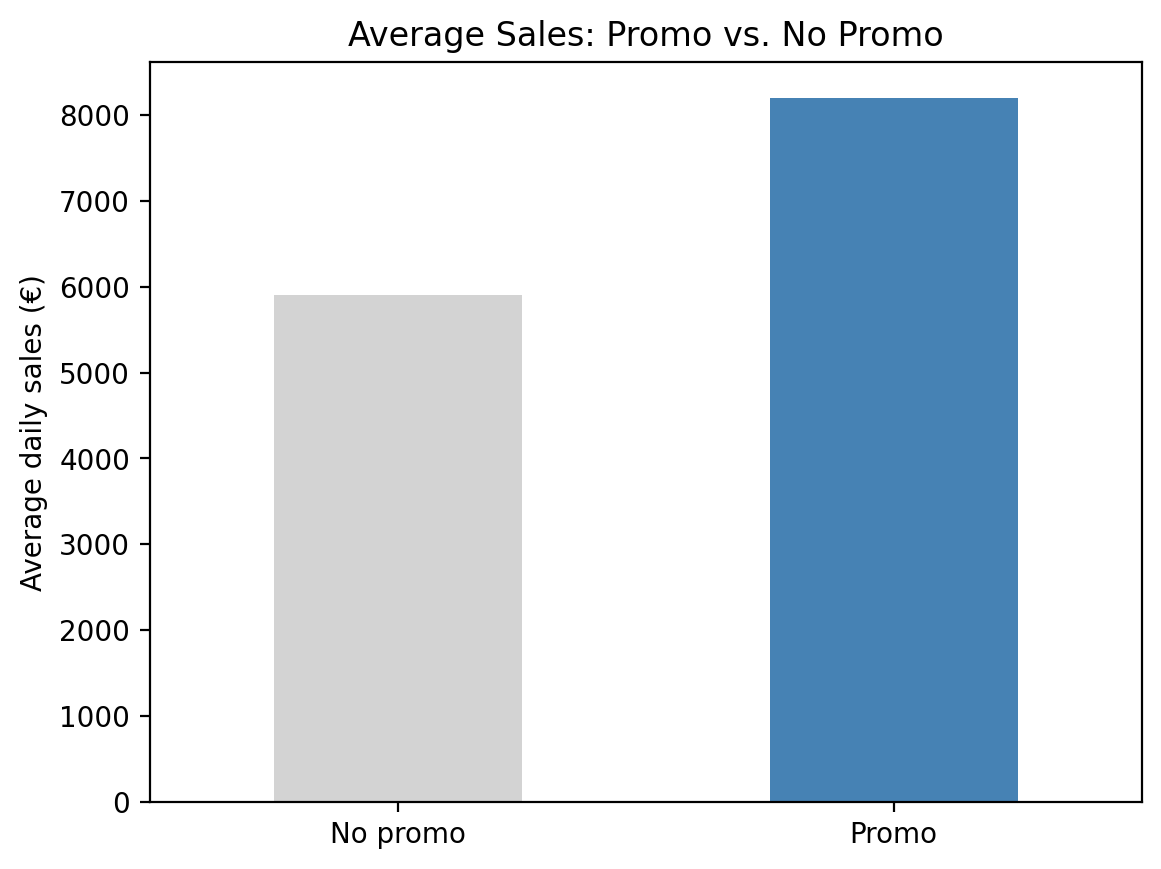

In [36]:
promo_means = train.groupby("Promo")["Sales"].mean()
print(promo_means)
print(f"\nPromo days sell {promo_means[1] / promo_means[0] - 1:.0%} more on average")

ax = promo_means.rename({0: "No promo", 1: "Promo"}).plot(kind="bar", color=["lightgray", "steelblue"], rot=0)
ax.set_ylabel("Average daily sales (€)")
ax.set_xlabel("")
ax.set_title("Average Sales: Promo vs. No Promo")
plt.show()

👀 Promotions clearly matter. This will be a useful feature.

### Day of week (open days only)

Earlier, Sunday looked terrible because most stores are closed. Now that we've dropped closed days, let's look again.

             avg_sales  n_days
DayOfWeek                     
Mon        8183.268535  124155
Tue        7050.444111  129472
Wed        6689.777158  127440
Thu        6754.217802  121909
Fri        7045.980529  124131
Sat        5856.989504  129567
Sun        8216.643037    3174


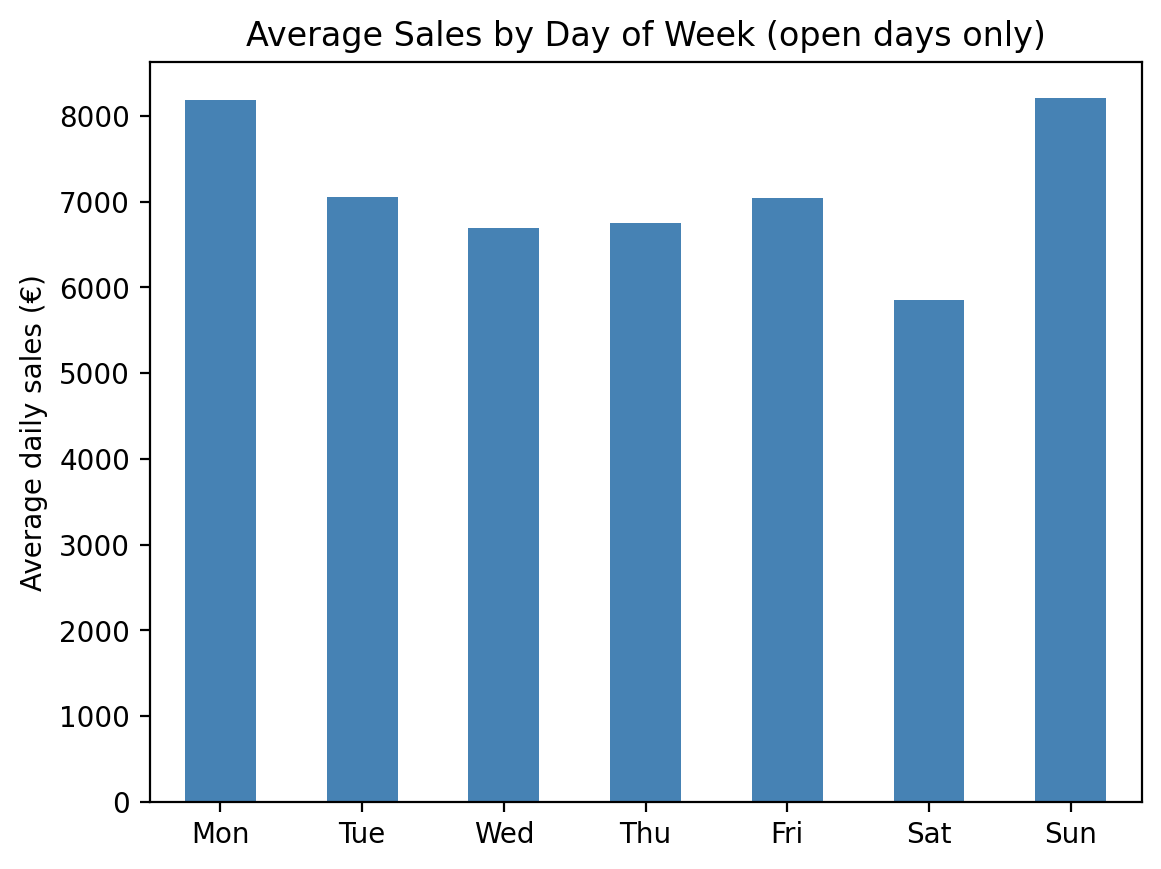

In [37]:
dow = train.groupby("DayOfWeek").agg(avg_sales=("Sales", "mean"), n_days=("Sales", "size"))
dow.index = dow.index.map(day_names)
print(dow)

ax = dow["avg_sales"].plot(kind="bar", color="steelblue", rot=0)
ax.set_ylabel("Average daily sales (€)")
ax.set_xlabel("")
ax.set_title("Average Sales by Day of Week (open days only)")
plt.show()

💬 **Discuss**
- How does Sunday look now? Check `n_days`: only a small number of stores open on Sundays. Which kinds of stores might those be? (Think train stations, tourist areas.)
- Does sales go up steadily from Monday to Sunday? No, so treating `DayOfWeek` as a number (1, 2, 3, ...) in a straight-line model would be wrong. We'll handle that in a moment.

### Month (Seasonality)

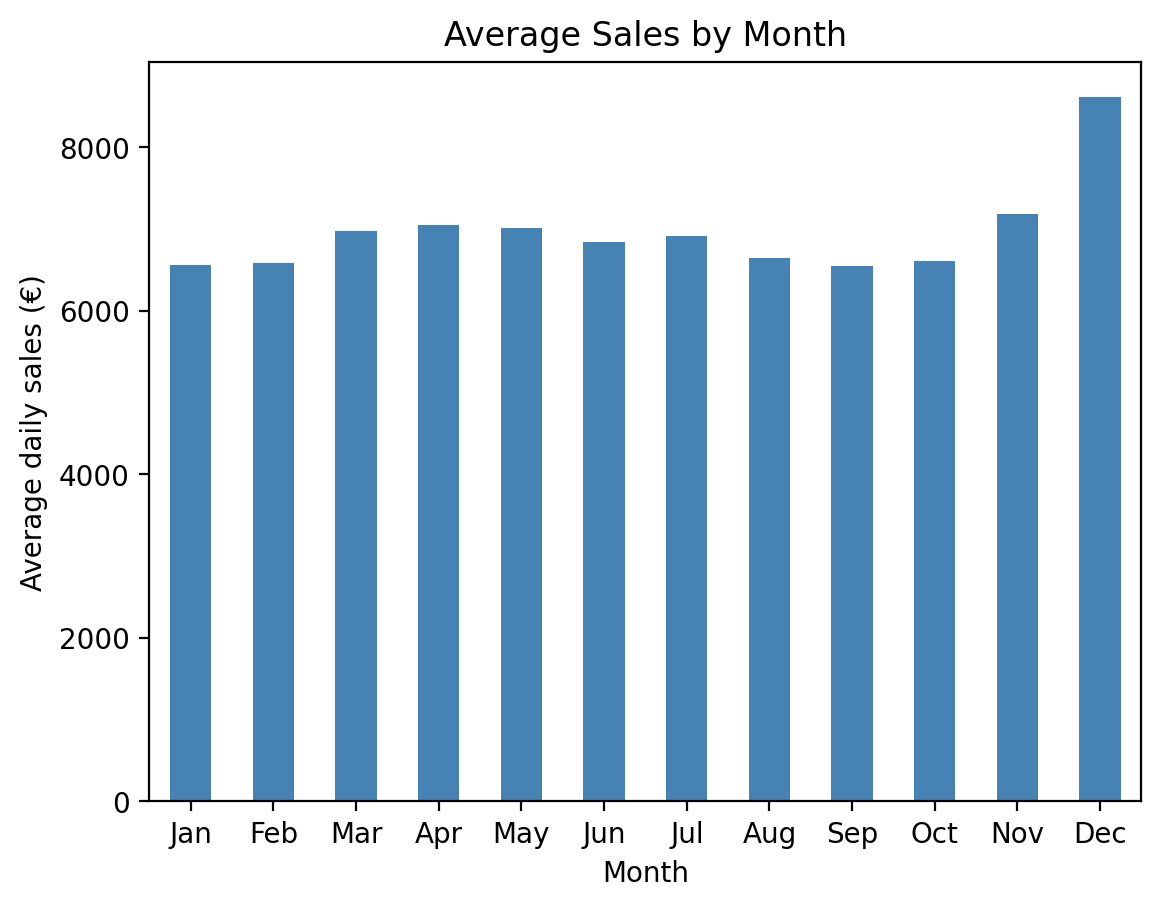

In [38]:
monthly = train.groupby("Month")["Sales"].mean()

monthly.index = monthly.index.map(lambda x: calendar.month_abbr[x])

ax = monthly.plot(kind="bar", color="steelblue", rot=0)
ax.set_ylabel("Average daily sales (€)")
ax.set_title("Average Sales by Month")
plt.show()

💬 **Discuss:** which month stands out, and why?

In [39]:
df['StateHoliday'] = df['StateHoliday'].astype(str)
holiday_names = {"0": "None", "a": "Public holiday", "b": "Easter", "c": "Christmas"}

state = (
    train.groupby("StateHoliday")["Sales"]
         .agg(avg_sales="mean", n_days="size")
         .rename(index=holiday_names)
)
state["vs. normal day"] = (state["avg_sales"] / state.loc["None", "avg_sales"] - 1).map("{:+.0%}".format)
state["avg_sales"] = state["avg_sales"].round(0)
state

,avg_sales,n_days,vs. normal day
StateHoliday,,,
None,6926.0,759110,+0%
Public holiday,8220.0,522,+19%
Easter,9888.0,145,+43%
Christmas,9744.0,71,+41%


💬 **Discuss**

Stores that are open on holidays sell **way more** than on a normal day. Christmas is about 40% higher!

But look at `n_days`. Out of roughly 760,000 store-days, only about 70 were stores open on Christmas.

- Does this mean holidays make *every* store sell more? Or could it be that only certain kinds of stores open on holidays in the first place?
- Where have we seen this before? (Hint: think back to Sunday.)
- If we only have 71 examples of something, how much should we trust the average?

### Store

Every store is different: location, size, neighborhood. How much do stores differ from each other?

count     1115.000000
mean      6905.068108
std       2378.958225
min       2703.012748
25%       5293.342514
50%       6579.514124
75%       7931.107541
max      21821.114407
Name: Sales, dtype: float64


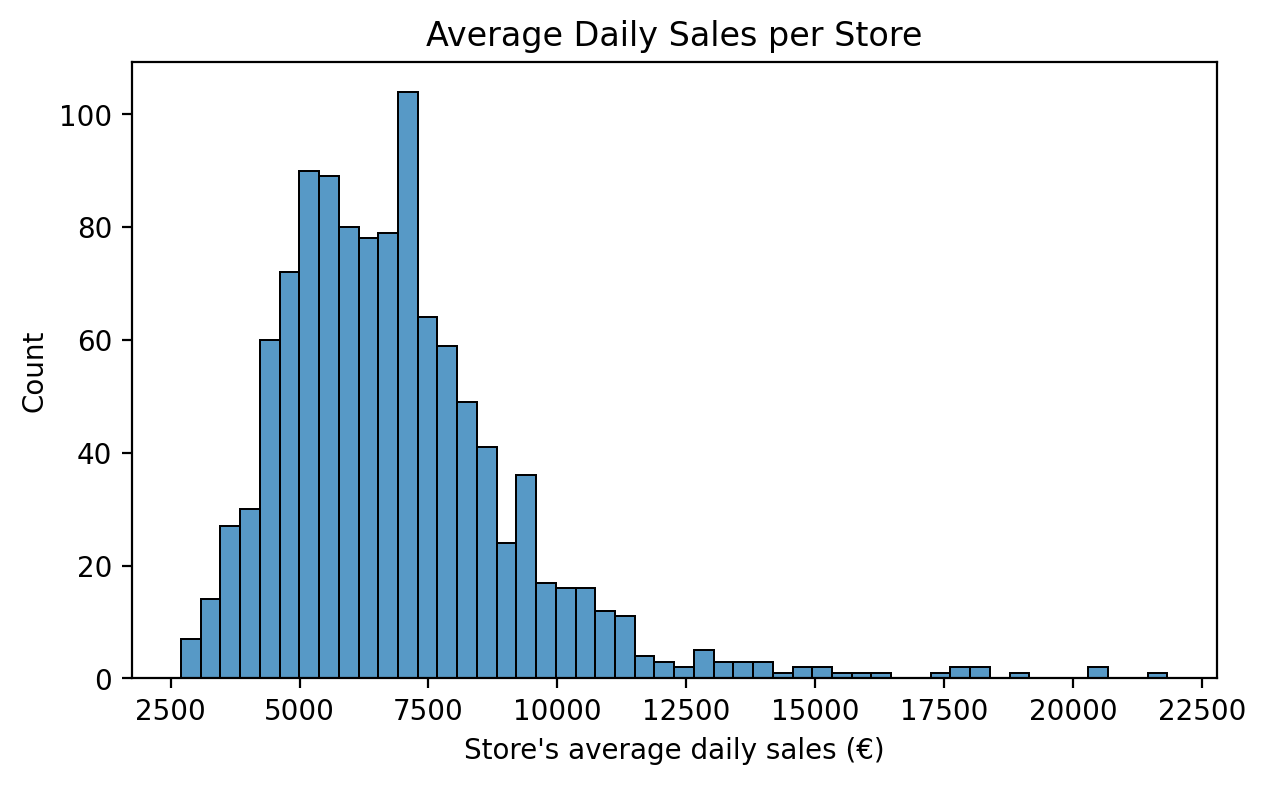

In [40]:
store_avg = train.groupby("Store")["Sales"].mean()
print(store_avg.describe())

plt.figure(figsize=(7, 4))
sns.histplot(store_avg, bins=50)
plt.xlabel("Store's average daily sales (€)")
plt.title("Average Daily Sales per Store")
plt.show()

👀 **Observe:** the busiest stores sell several times more than the quietest ones. **Which store it is** is probably the most important thing we know!

But we can't plug in the store ID as a number (store 1000 isn't "more" than store 2). Instead, we'll give the model each **store's average daily sales in the training data**. This is called **target encoding**.

⚠️ We compute those averages from **`train` only**. If we used the test set, we'd be leaking the answers into a feature again.

## 7. Multiple linear regression

Now the model uses several features at once:

$$\text{Sales} = b_0 + b_1 x_1 + b_2 x_2 + \dots$$

Each coefficient $b_i$ means: how much sales change when $x_i$ goes up by 1, **holding all the other features constant**.

### Preparing the features
- **`StoreAvgSales`**: each store's training-set average (from the plot above).
- **One-hot encoding** for the categories (`DayOfWeek`, `Month`, `StateHoliday`). `pd.get_dummies` turns one column into several 0/1 columns, e.g. `DayOfWeek_6` is 1 on Saturdays.
  - `drop_first=True` drops one category per feature to act as the **baseline** (Monday, January, no holiday). Every other coefficient is compared to that baseline.
- The test set only covers May–July, so it has no `Month_12` column. `.reindex(...)` gives test the exact same columns as train, filling the missing ones with 0.

In [41]:
def make_features(data):
    X = data[["Promo", "SchoolHoliday", "DayOfWeek", "Month", "StateHoliday"]].copy()
    X["StoreAvgSales"] = data["Store"].map(store_avg)   # store_avg was computed from train only
    X = pd.get_dummies(X, columns=["DayOfWeek", "Month", "StateHoliday"], drop_first=True, dtype=int)
    return X

X_train_all = make_features(train)
X_test_all  = make_features(test).reindex(columns=X_train_all.columns, fill_value=0)

print(X_train_all.shape, X_test_all.shape)
X_train_all.head()

(759848, 23) (84490, 23)


,Promo,SchoolHoliday,StoreAvgSales,DayOfWeek_2,DayOfWeek_3,DayOfWeek_4,DayOfWeek_5,DayOfWeek_6,DayOfWeek_7,Month_2,...,Month_6,Month_7,Month_8,Month_9,Month_10,Month_11,Month_12,StateHoliday_a,StateHoliday_b,StateHoliday_c
102580,1,0,4788.041076,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
102581,1,0,4945.985876,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
102582,1,0,6918.414773,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
102583,1,0,9601.668079,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
102584,1,0,4674.809388,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### ✏️ Fit two multiple regression models
We'll see how much each group of features helps.

- **Model A, calendar only:** every column of `X_train_all` **except** `StoreAvgSales`.
- **Model B, calendar + store:** every column of `X_train_all`.

For each model:
1. Pick the feature columns (for Model A, `X_train_all.drop(columns="StoreAvgSales")` works).
2. Create a `LinearRegression()` and `.fit()` it on the training features and `y_train`.
3. `.predict()` on the matching test features.
4. Compute test **R²**, **RMSE**, and **MAE** , like you did for the simple model.

*Tip:* you'll be computing those three metrics a lot, so try writing a small function for it.

In [42]:
def evaluate(name, y_true, y_pred):
    return {
        "model": name,
        "R²": r2_score(y_true, y_pred),
        "RMSE (€)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE (€)": mean_absolute_error(y_true, y_pred),
    }

# Model A: calendar only
calendar_cols = X_train_all.columns.drop("StoreAvgSales")
model_a = LinearRegression().fit(X_train_all[calendar_cols], y_train)
pred_a = model_a.predict(X_test_all[calendar_cols])

# Model B: calendar + store
model_b = LinearRegression().fit(X_train_all, y_train)
pred_b = model_b.predict(X_test_all)

results = [
    evaluate("Customers only (leaky!)", y_test, y_pred_simple),
    evaluate("A: calendar only", y_test, pred_a),
    evaluate("B: calendar + store", y_test, pred_b),
]

### How good is "good"? 

A model is only impressive if it beats a simple guess. The simplest reasonable guess: **predict each store's usual average**.

In [43]:
baseline_pred = test["Store"].map(store_avg)
results.append(evaluate("Baseline: store average", y_test, baseline_pred))

pd.DataFrame(results).set_index("model").round(3)

,R²,RMSE (€),MAE (€)
model,,,
Customers only (leaky!),0.632,1862.606,1319.496
A: calendar only,0.139,2849.633,2008.705
B: calendar + store,0.765,1487.138,1068.583
Baseline: store average,0.621,1889.203,1405.246


💬 **Discuss**
- How much did adding the store information help, going from A to B?
- Does Model B beat the baseline? By how much? (that gap is what promo, day of week, month, and holidays add **on top of** knowing the store).



*Your answer:*

👀 **Observe**
- Compare the leaky Customers model with Model B. However well it scores, we couldn't actually use it, so its score doesn't count.
- Our "look at the features first" step predicted most of this: the store histogram showed store was the biggest factor, and it was.

## 8. Checking the model

### Coefficients

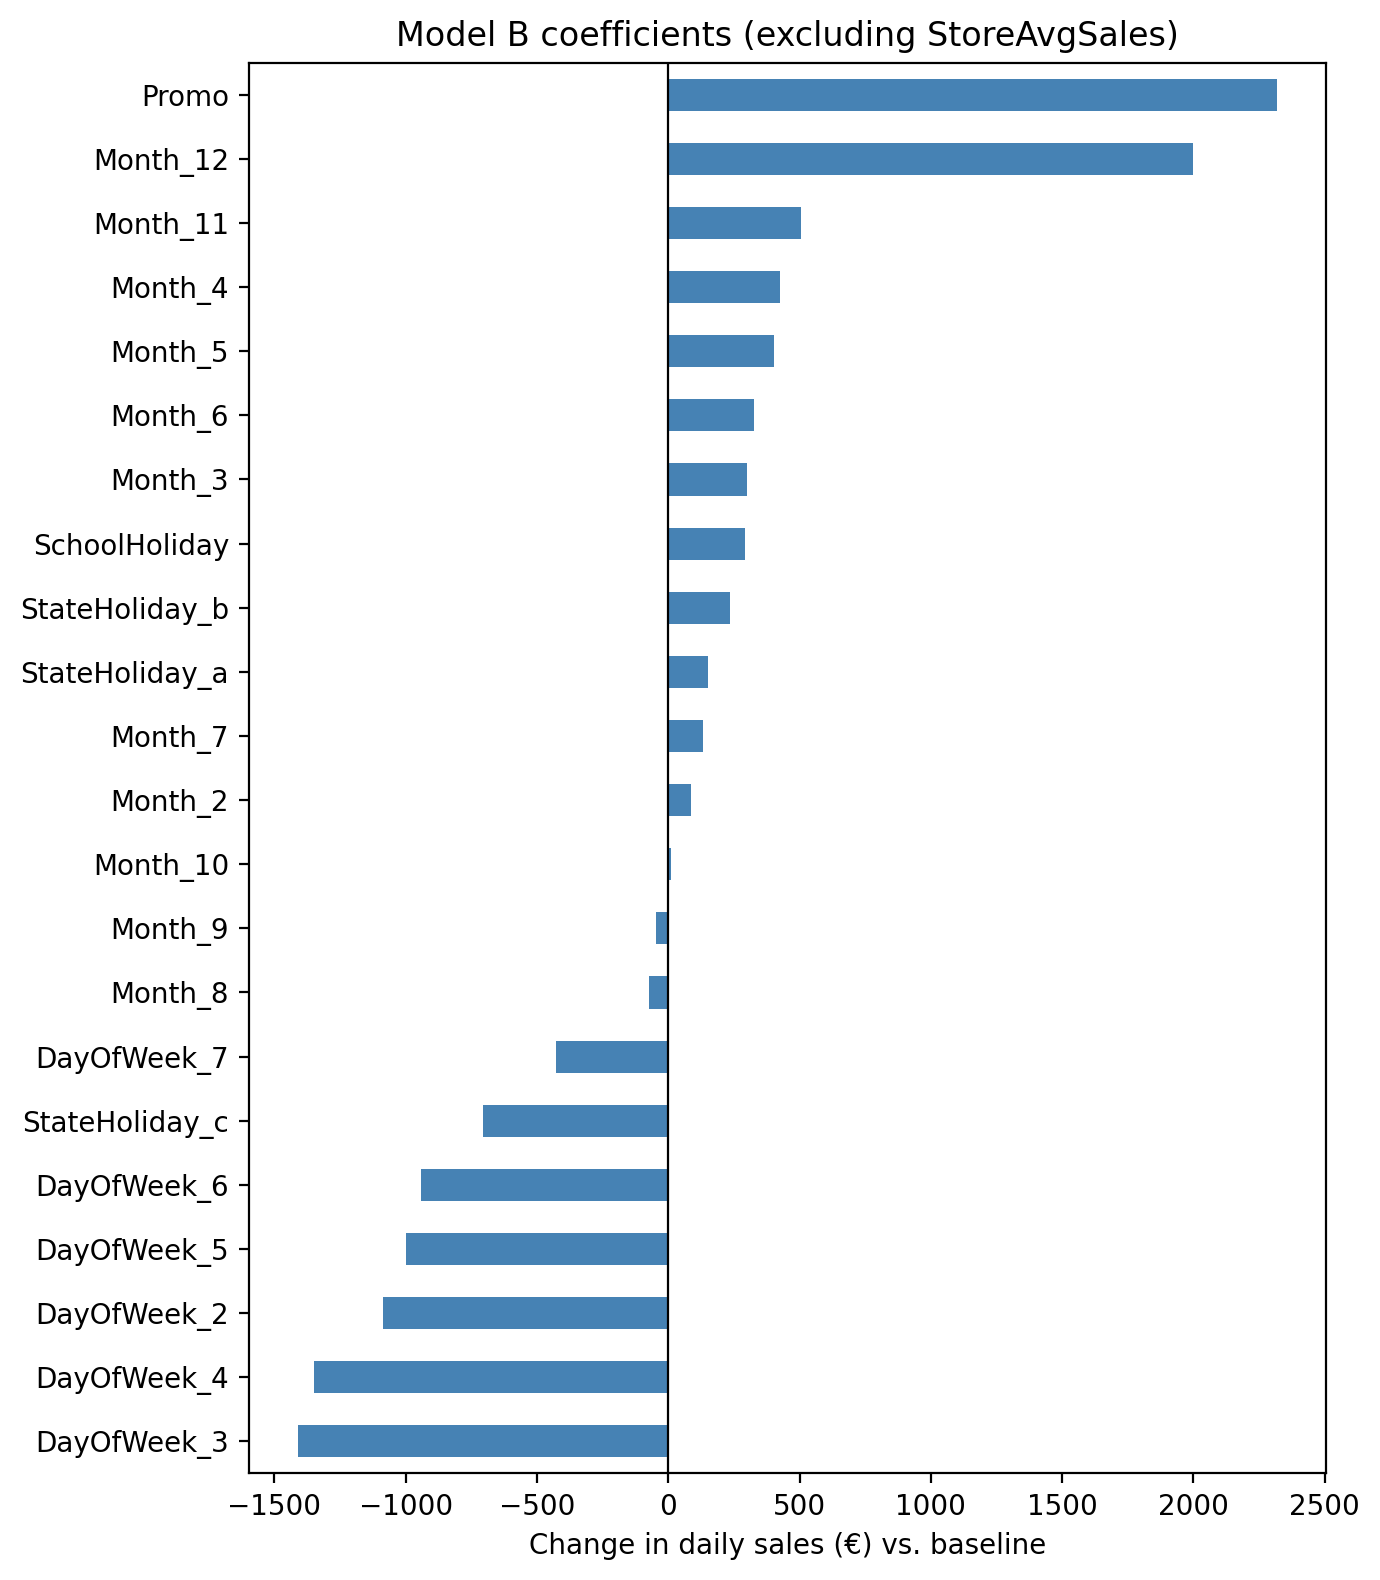

Intercept: -438
StoreAvgSales coefficient: 1.000
Promo coefficient: 2,320


In [44]:
coefs = pd.Series(model_b.coef_, index=X_train_all.columns).sort_values()

plt.figure(figsize=(7, 8))
coefs.drop("StoreAvgSales").plot(kind="barh", color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Change in daily sales (€) vs. baseline")
plt.title("Model B coefficients (excluding StoreAvgSales)")
plt.tight_layout()
plt.show()

print(f"Intercept: {model_b.intercept_:,.0f}")
print(f"StoreAvgSales coefficient: {coefs['StoreAvgSales']:.3f}")
print(f"Promo coefficient: {coefs['Promo']:,.0f}")

**How to read these** (each one is "holding everything else constant"):
- **`Promo`**: running a promo adds about this many euros to a day's sales, for the same store on the same kind of day.
- **`DayOfWeek_k`**: sales on that day compared to **Monday** (the dropped baseline). Negative means lower than Monday.
- **`Month_k`**: compared to **January**. Find December.
- **`StoreAvgSales`**: close to 1 means "start from the store's usual level," and the other features push it up or down from there.

`StoreAvgSales` is left off the chart because its scale (per euro of store average) isn't comparable to the 0/1 features.

### Residuals
A residual is **actual minus predicted**. If the model captured the pattern, residuals should look like random noise centered on 0.

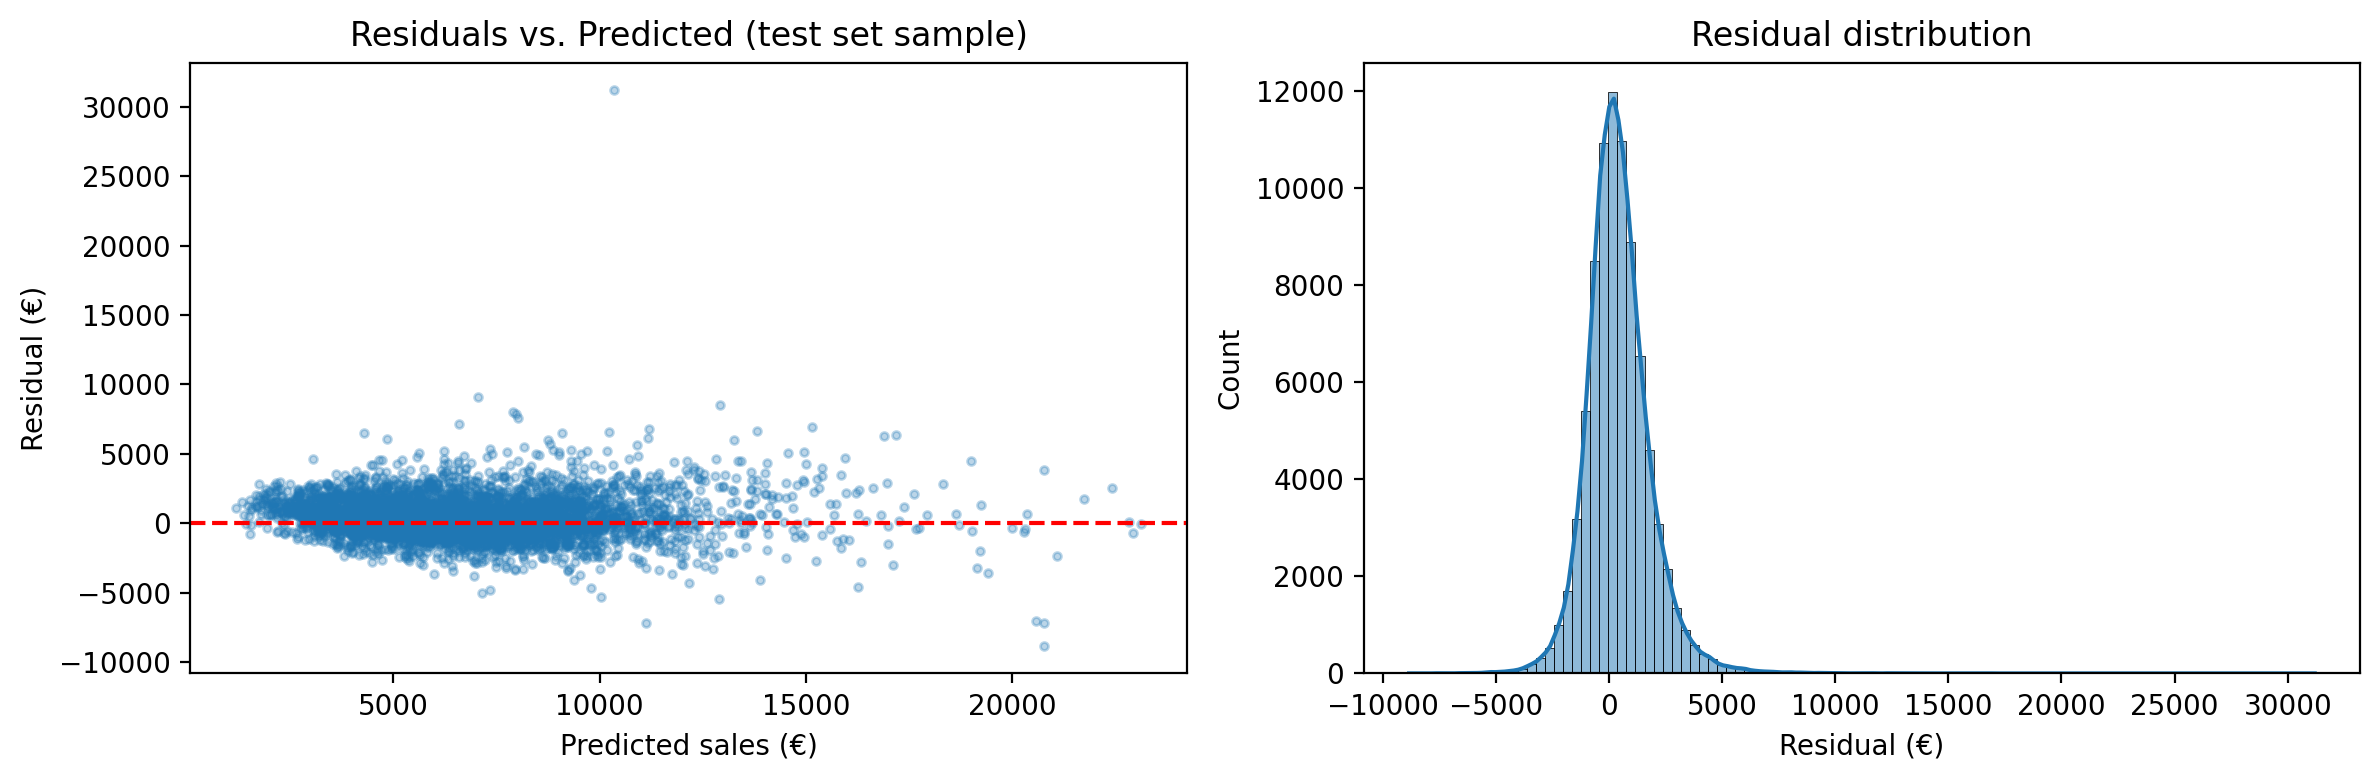

Mean residual on test: €428


In [45]:
resid_b = y_test - pred_b

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

idx = np.random.default_rng(42).choice(len(y_test), 5000, replace=False)
axes[0].scatter(pred_b[idx], resid_b.iloc[idx], alpha=0.3, s=8)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted sales (€)")
axes[0].set_ylabel("Residual (€)")
axes[0].set_title("Residuals vs. Predicted (test set sample)")

sns.histplot(resid_b, bins=100, kde=True, ax=axes[1])
axes[1].set_xlabel("Residual (€)")
axes[1].set_title("Residual distribution")

plt.tight_layout()
plt.show()

print(f"Mean residual on test: €{resid_b.mean():,.0f}")


💬 **Discuss**
- Is the spread of residuals the same everywhere, or does it **fan out** for bigger predicted sales? A fan shape means errors grow with store size (the same thing we saw in the Customers scatter).
- Is the mean residual close to 0? If it's clearly positive or negative, the model is systematically over- or under-predicting the test months. Why might a model trained on 2013–early 2015 be off for summer 2015?
- Are there long tails? Those are days the model badly missed. What might be going on those days?

## 9. Wrap-up

**Takeaways**
1. **Look before you fit.** Exploring showed us closed days, the Sunday effect, December, and how much stores differ. All of that shaped the model.
2. **Split by time** when you're predicting the future.
3. **Watch for leakage.** Ask: would I actually know this feature at prediction time?
4. **Categories aren't numbers.** Use one-hot encoding (or target encoding for things like store ID).
5. **Always compare to a baseline.** A model is only as good as what it beats.

### Challenges
- **Log the target.** Fit Model B on `np.log(Sales)` and convert predictions back with `np.exp`. Does that fix the fan-shaped residuals? Does RMSE improve?
- **Use `store.csv`.** Rossmann also gives store info: `StoreType`, `Assortment`, `CompetitionDistance`. Merge it in on `Store` and look at each feature before adding it.
- **Interaction.** Does a promo help some store types more than others? Try a `Promo × StoreType` feature.